# Transformation Equations:  LSST DP2 <--> UBVR<sub>c</sub>I<sub>c</sub>

_Christina L. Adair, Douglas L. Tucker, Meagan N. Porter_

_2026.08.1_

## 1. Import Modules

In [1]:
import numpy as np
import pandas as pd

from lsst.daf.butler import Butler
import lsst.geom as geom

import pyvo 
from pyvo import registry

import os
import sys
import glob
import math
import datetime
import re

import pickle

from tqdm.notebook import tqdm

from collections import OrderedDict as odict

from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord
import astropy.units as u

import fitsio

from scipy import interpolate
from scipy.optimize import leastsq

import healpy as hp

import plotly
from plotly.offline import download_plotlyjs, plot, iplot
import plotly.graph_objs as go

from IPython.display import Markdown, display

import matplotlib.pyplot as plt

%matplotlib inline

## 2. Input Parameters

In [2]:
# LSST-->UBVRcIc (toLSST=False) or UBVRcIc-->LSST (toLSST=True)...
toLSST = True
#toLSST = False

if toLSST:
    # List of LSST bands on which to run the transform fit...
    bandList = ['u_LSST','g_LSST', 'r_LSST', 'i_LSST', 'z_LSST', 'y_LSST']
    # If UBVRcIc-->LSST, then the mag and color to fit against are UBVRcIc...
    # Dictionary of corresponding bands from the other survey...
    matchBand_dict = {'u_LSST': 'U','g_LSST':'V', 'r_LSST':'R', 'i_LSST':'I', 'z_LSST':'I', 'y_LSST':'I'}
    # Color to fit against...
    color_name_1_dict = {'u_LSST':'UB','g_LSST':'BV', 'r_LSST':'RI', 'i_LSST':'RI', 'z_LSST':'RI', 'y_LSST':'RI'}
    # Name of color_name_1 as the label in the QA plots...
    colorLabel_1_dict = {'u_LSST': '$(U-B)$','g_LSST':'$(B-V)$', 'r_LSST':'$(R-I)$', 'i_LSST':'$(R-I)$', 'z_LSST':'$(R-I)$', 'y_LSST':'$(R-I)$'}
    # Color limits defining disjoint branches of the dmag vs. color plots
    #  (each branch will be fit separately)...
    color_limits_1_dict = {'u_LSST':[-10.,10.],
                           'g_LSST':[-10.,10.], 
                           'r_LSST':[-10.,10.], 
                           'i_LSST':[-10.,10.],
                           'z_LSST':[-10.,10.],
                           'y_LSST':[-10.,0.6,10.]}
    
    
else:
    # List of UBVRcIc bands on which to run the transform fit...
    bandList = ['U', 'B', 'V', 'R', 'I']
    #bandList = ['V']
    # If LSST-->UBVRcIc, then the mag and color to fit against are LSST...
    # Dictionary of corresponding bands from the other survey...
    matchBand_dict = {'U':'u_LSST', 'B':'g_LSST', 'V':'g_LSST', 'R':'r_LSST', 'I':'i_LSST'}
    # Color to fit against...
    color_name_1_dict = {'U':'gi_LSST', 'B':'gi_LSST', 'V':'gi_LSST', 'R':'gi_LSST', 'I':'gi_LSST'}
    # Name of color_name_1 as the label in the QA plots...
    colorLabel_1_dict = {'U':'$(g-i)_{LSST}$', 'B':'$(g-i)_{LSST}$', 'V':'$(g-i)_{LSST}$', 'R':'$(g-i)_{LSST}$', 'I':'$(g-i)_{LSST}$'}
    # Color limits defining disjoint branches of the dmag vs. color plots
    #  (each branch will be fit separately)...    
    color_limits_1_dict = {'U':[-10.,10.], 
                           'B':[-10.,1.6,10.], 
                           'V':[-10.,1.6,10.], 
                           'R':[-10.,1.6,10.],
                           'I':[-10.,1.6,10.]}


# Order of polynomial fits...
norder = 1

# Sigma-clipping parameters...
nsigma = 3.0
niter = 3

# LSST data
collection = 'LSSTCam/runs/DRP/DP2'
repo = 'dp2_prep'
skymap = 'lsst_cells_v2'
instrument = 'LSSTCam'

# UBVRcIc TAP service  (does not exist!)
UBVRcIc_tap_url = 'https://tapvizier.cds.unistra.fr/TAPVizieR/tap'

#Aitoff file
aitoffPlotFileName = 'UBVRcIc_LSST_DP2.png'

# Use match file?
useMatchFile = True

# Name of the match file
matchFile = 'match_UBVRcIc_LSST_DP2.csv'

# Base name of QA plot output files...
if toLSST:
    qaFileBaseName = 'qaPlot.UBVRcIc_to_LSST_DP2.fit'
else:
    qaFileBaseName = 'qaPlot.LSST_DP2_to_UBVRcIc.fit'

# Write a Markdown-formatted summary table of the fits?
write_md_file = True
if write_md_file:
    # Auto-name the .md file based on qaFileBaseName
    md_filename = f"{qaFileBaseName}.qa_summary.md"

# Verbosity level (0, 1, 2, 3, ...)
verbose = 2


## 3. Define Useful Functions

In [3]:
# Useful class to stop "Run All" at a cell 
#  containing the command "raise StopExecution"
class StopExecution(Exception):
    def _render_traceback_(self):
        pass

In [4]:
def cross_match_catalogs(df1, df2, ra_name_1, dec_name_1, ra_name_2, dec_name_2):

    # Create SkyCoord objects for both dataframes
    coords1 = SkyCoord(ra=df1[ra_name_1].values*u.degree, 
                       dec=df1[dec_name_1].values*u.degree)

    coords2 = SkyCoord(ra=df2[ra_name_2].values*u.degree, 
                       dec=df2[dec_name_2].values*u.degree)

    # Match coordinates
    max_sep = 3 * u.arcsec  # Maximum separation
    idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

    # Create mask for matches within max_sep
    mask = d2d < max_sep

    # Additional mask to ensure indices are valid
    valid_idx_mask = idx[mask] < len(df2)
    combined_mask = mask.copy()
    combined_mask[mask] = valid_idx_mask
    
    # Create a new dataframe with matches
    matches = df1[combined_mask].copy()
    matches['match_idx'] = idx[combined_mask]  # Index of matching object in df2
    matches['separation_arcsec'] = d2d[combined_mask].arcsec  # Separation in arcseconds

    # Add columns from df2 for the matches
    for col in df2.columns:
        #matches[f'match_{col}'] = df2.loc[idx[mask], col].values
        # This is a safer way to to this, avoid out-of-bound indices:
        matches[f'match_{col}'] = df2.iloc[idx[combined_mask]][col].values

    # If multiple matches exist for the same source in df1, keep only the closest one
    matches = matches.loc[matches.groupby(matches.index)['separation_arcsec'].idxmin()]

    # If you want to see which objects in df1 had no matches:
    unmatched = df1[~combined_mask]

    return matches, unmatched

In [5]:

def transform1ColorQAPlots1a(dmag, color1, res, norder, title, plot1Text, dmagName, colorLabel1, rms, outputFileName):

    # Prepare QA plots...
    #fig = plt.figure(figsize=(10,5))
    #fig = plt.figure(figsize=(40,20))
    fig = plt.figure(figsize=(20,10))
    fig.subplots_adjust(hspace=0.3)
    #fig.suptitle("This is a supertitle!")
    plt.rcParams.update({'font.size': 24})
    
    # We will exclude the lowest and highets 0.01% of color1, color2, 
    #  dmag, and residuals when plotting the QA figures...
    color1_desc = color1.describe(percentiles=[0.0001, 0.001, 0.01, 0.99, 0.999, 0.9999])
    dmag_desc = dmag.describe(percentiles=[0.0001, 0.001, 0.01, 0.99, 0.999, 0.9999])
    #res_desc = df.res.describe(percentiles=[0.0001, 0.001, 0.01, 0.99, 0.999, 0.9999])
    res_desc = res.describe(percentiles=[0.0001, 0.001, 0.01, 0.99, 0.999, 0.9999])
    #color1_min = color1_desc['1%']
    #color1_max = color1_desc['99%']
    #color1_min = color1_desc['min']
    #color1_max = color1_desc['max']
    #dmag_min = dmag_desc['1%']
    #dmag_max = dmag_desc['99%']
    #res_min = res_desc['1%']
    #res_max = res_desc['99%']
    color1_min = color1_desc['0.01%']
    color1_max = color1_desc['99.99%']
    dmag_min = dmag_desc['0.01%']
    dmag_max = dmag_desc['99.99%']
    res_min = res_desc['0.01%']
    res_max = res_desc['99.99%']
    # What the heck; let's just set this to -0.10 mag --> +0.10 mag...
    #res_min = -0.10
    #res_max = +0.10

    
    # Plot 1:  Descriptive text...
    #plt.subplot(231)
    plt.subplot(221)
    plt.text(0.1,0.80,title,fontsize=24)
    plt.text(0.00,0.40,plot1Text,fontsize=12)
    plt.axis('off')

    
    # Plot 2:  2D hexbin histogram of dmag vs. color1...
    #plt.subplot(232) 
    plt.subplot(222)
    if len(dmag) < 1000:
        plt.scatter(color1, dmag, alpha=0.75)
        #hb=plt.hexbin(color1, dmag, gridsize=100, cmap='inferno_r')
    else:
        hb=plt.hexbin(color1, dmag, gridsize=100, bins='log', cmap='inferno')
    plt.axis([color1_min, color1_max, dmag_min, dmag_max])
    plt.xlabel(colorLabel1)
    plt.ylabel(dmagName)
    if len(dmag) >= 1000:
        cb = fig.colorbar(hb)
        cb.set_label('log10(N)')
    plt.grid(color='blue')
    plt.grid(True)


    # Plot 3:  1d histogram of residuals...
    #plt.subplot(234) 
    plt.subplot(223) 
    #plt.hist(df.loc[:,'res'],bins=100)
    if len(res) < 100:
        plt.hist(res,bins=10)
    else:
        plt.hist(res,bins=100)
    plt.xlabel('residuals [mag]')
    plt.ylabel('Number')
    plt.grid(True)
    plt.grid(color='blue')

    
    # Plot 4:  2d hexbin histogram of residuals vs. color1...
    #plt.subplot(235) 
    plt.subplot(224)
    if len(res) < 1000:
        plt.scatter(color1, res, alpha=0.75)
        #hb = plt.hexbin(color1, res, gridsize=100, cmap='inferno_r')
    else:
        hb = plt.hexbin(color1, res, gridsize=100, bins='log', cmap='inferno')
    plt.axis([color1_min, color1_max, res_min, res_max])
    plt.xlabel(colorLabel1)
    plt.ylabel('residuals [mag]')
    if len(res) >= 1000:
        cb = plt.colorbar(hb)
        cb.set_label('log10(N)')
    plt.grid(True)
    plt.grid(color='blue')

    
    # Plot...
    plt.tight_layout()
    #plt.show()
    plt.savefig(outputFileName)

    return 0
    

In [6]:
# Kudos to Claude-3.5-Sonnet for improving on old outlier rejection code...

def poly_fit_with_sigma_clip(x, y, degree=1, sigma=3.0, maxiters=5):
    """
    Perform polynomial fit with iterative sigma clipping
    
    Parameters:
    -----------
    x : array-like
        Independent variable
    y : array-like 
        Dependent variable
    degree : int
        Degree of polynomial fit
    sigma : float
        Sigma clipping threshold
    maxiters : int
        Maximum number of sigma clipping iterations
        
    Returns:
    --------
    coeffs : array
        Polynomial coefficients
    mask : array
        Boolean mask indicating non-clipped points
    rms : float
        RMS of residuals
    """

    # Import relevant modules
    import numpy as np
    from astropy.stats import sigma_clip
    
    # Initial fit using all points
    x = np.asarray(x)
    y = np.asarray(y)
    mask = np.ones_like(x, dtype=bool)
    
    for _ in range(maxiters):
        print(len(x[mask]), len(y[mask]), len(mask))

        # Fit polynomial to non-masked points
        coeffs, cov = np.polyfit(x[mask], y[mask], degree, cov=True)
        
        # Calculate residuals
        yfit = np.polyval(coeffs, x)
        residuals = y - yfit
        
        # Update mask with sigma clipping
        new_mask = ~sigma_clip(residuals, sigma=sigma).mask
        
        # Check for convergence
        if np.array_equal(mask, new_mask):
            break
        
        mask = new_mask
    
    # Calculate final RMS
    final_residuals = y[mask] - np.polyval(coeffs, x[mask])
    rms = np.sqrt(np.mean(final_residuals**2))

    print(len(x[mask]), len(y[mask]), len(mask))

    # Calculate coefficient errors from diagonal of covariance matrix
    coeff_errors = np.sqrt(np.diag(cov))
        
    return coeffs, coeff_errors, x[mask], y[mask], final_residuals, rms

In [7]:
# Kudos to Copilot ChatGPT-5 for these functions for generating Markdown output 
#  of the fit equations...
# See:  https://copilot.microsoft.com/shares/Nopgin8hutEqEmjqJkteY

def latexify_label(label: str) -> str:
    """Strip $ and convert underscores to LaTeX subscripts."""
    label = label.strip('$')
    return re.sub(r'_(\w+)', r'_{\1}', label)

def latexify_name(name: str) -> str:
    """Convert underscores in names to LaTeX subscripts."""
    return re.sub(r'_(\w+)', r'_{\1}', name)

def make_eq_str(dmagName, p_branch, colorLabel_1, norder):
    """
    Build a LaTeX-formatted transformation equation for Markdown.
    Ensures all terms are inside a single $...$ block with proper signs.
    """
    label = latexify_label(colorLabel_1)           # e.g., (g-i)_{LSST}
    dmagName_math = latexify_name(dmagName)        # e.g., U - u_{LSST}

    terms = []
    power = norder
    for coeff in p_branch:
        if power == 0:
            # Constant term: no variable
            terms.append(f"{coeff:+.3f}")
        elif power == 1:
            # Linear term
            terms.append(f"{coeff:+.3f} {label}")
        else:
            terms.append(f"{coeff:+.3f} {label}^{power}")
            # Higher-order term
        power -= 1

    # Join all terms with spaces; signs are already included in coeff formatting
    eq_body = " ".join(terms)
    return f"${dmagName_math} = {eq_body}$"

def make_range_str(color_limits, colorLabel_1, ibranch):
    label = latexify_label(colorLabel_1)
    # Use LaTeX \leq for "less than or equal to"
    return (f"${color_limits[ibranch]:.1f} < {label} \\leq "
            f"{color_limits[ibranch+1]:.1f}$")

def make_output_filename(base, magName, magName_match, color_name_1, norder):
    return f"{base}.dmag_{magName}-{magName_match}.{color_name_1}.norder{norder}.qa1.png"


In [8]:
# Kudos to Copilot ChatGPT-5 for improving the plot text generation

def make_plot_text(dmagName, p_branch, colorLabel_1, norder,
                   color_limits, ibranch, stddev_branch):
    """
    Build a descriptive text string for plots, valid for any polynomial order.
    Example output:
    "g - r = -0.041 -0.302*(g-i)   [0.2 < (g-i) <= 2.5]   [rms: 0.022]"
    """
    terms = []
    power = norder
    for coeff in p_branch:
        if power == 0:
            # Constant term, but still include sign
            terms.append(f"{coeff:+.3f}")
        elif power == 1:
            terms.append(f"{coeff:+.3f}*{colorLabel_1}")
        else:
            terms.append(f"{coeff:+.3f}*{colorLabel_1}^{power}")
        power -= 1

    poly_str = " ".join(terms)

    lo = color_limits[ibranch]
    hi = color_limits[ibranch+1]
    range_str = f"[{lo:.1f} < {colorLabel_1} <= {hi:.1f}]"
    rms_str = f"[rms: {stddev_branch:.3f}]"

    return f"{dmagName} = {poly_str}  {range_str}  {rms_str}"


## X. Read in Matched Catalog

In [9]:
## Check to make sure matchFile exists...
if useMatchFile:
    if os.path.isfile(matchFile)==False:
        print("""ERROR:  matchFile %s does not exist...""" % (matchFile))
    if verbose > 0:
        print('matchFile: ', matchFile)


matchFile:  match_UBVRcIc_LSST_DP2.csv


In [10]:
if useMatchFile:
    tab = Table.read(matchFile, format='csv')
    display(tab)

tractId,field,coord_ra,coord_dec,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_extendedness,u_psfFlux_flag,g_psfFlux,g_psfFluxErr,g_ap12Flux,g_ap12FluxErr,g_extendedness,g_psfFlux_flag,r_psfFlux,r_psfFluxErr,r_ap12Flux,r_ap12FluxErr,r_extendedness,r_psfFlux_flag,i_psfFlux,i_psfFluxErr,i_ap12Flux,i_ap12FluxErr,i_extendedness,i_psfFlux_flag,z_psfFlux,z_psfFluxErr,z_ap12Flux,z_ap12FluxErr,z_extendedness,z_psfFlux_flag,y_psfFlux,y_psfFluxErr,y_ap12Flux,y_ap12FluxErr,y_extendedness,y_psfFlux_flag,match_idx,separation_arcsec,match_recno,match_Id,match_GaiaEDR3,match_GaiaDR2,match_Name,match_Collect,match_RAJ2000,match_DEJ2000,match_RAGdeg,match_DEGdeg,match_Umag,match_e_Umag,match_nU,match_Bmag,match_e_Bmag,match_nB,match_Vmag,match_e_Vmag,match_nV,match_Rmag,match_e_Rmag,match_nR,match_Imag,match_e_Imag,match_nI,match_BinFlag,match_VarFlag,match_HighQual,match_Dist,match_b_Dist,match_B_Dist,match_E(B-V),match_e_E(B-V),match_RV,match_e_RV,match_MethRV,match_StarType,match_Methstar,match_Teff,match_e_Teff,match_logg,match_e_logg,match_[Fe/H],match_e_[Fe/H],match_Methp
int64,str7,float64,float64,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,str5,float64,float64,float64,float64,float64,str5,int64,float64,int64,int64,int64,int64,str19,str7,float64,float64,float64,float64,float64,float64,int64,float64,float64,int64,float64,float64,int64,float64,float64,int64,float64,float64,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,str17,str7,str49,float64,float64,float64,float64,float64,float64,str9
2234,unknown,58.88845883330013,-49.85108205575262,--,--,--,--,--,True,863525.06,251.65637,868015.0,219.54434,0.0,False,1280588.2,342.01755,1286668.4,300.50803,0.0,False,1380812.9,217.43852,1445230.2,197.22507,--,False,1496933.4,319.7023,1503429.6,326.6262,0.0,False,1518686.0,1084.0571,1542005.6,1412.4005,0.0,False,152394,0.03908332265441644,173178,90374,4829762918458860544,4829762918458860544,AM1-S185,Stetson,58.88845562935,-49.85109271387,58.8884515780571,-49.8510865630336,--,--,0,16.907,0.0088,20,16.286,0.0094,7,15.901,0.0066,18,--,--,0,0,0,0,2946.9812,2732.3284,3184.67,0.012,0.00952627944162882,--,--,--,--,--,--,--,--,--,--,--,--
2234,unknown,58.81000779077281,-49.848705735442714,--,--,--,--,--,True,217960.55,128.93872,217380.38,128.67128,0.0,False,711489.06,205.16922,713240.1,189.2794,0.0,False,1451059.2,244.74765,1541122.5,212.29224,--,False,2164573.0,369.0958,2205447.0,348.57358,--,False,2917471.2,1879.9231,2664111.5,1980.3258,0.0,False,152397,0.3310118452198972,173181,90382,4829765564158665728,4829765564158665728,AM1-S152,Stetson,58.8098653396,-49.84870157772,58.809936491261,-49.8487043730387,--,--,0,18.827,0.0098,20,17.351,0.0116,7,16.372,0.007,18,--,--,0,0,0,0,372.62042,366.69754,377.2985,0.011,0.00668954408012983,--,--,--,--,--,--,--,--,--,--,--,--
2234,unknown,58.69783332313198,-49.847907857603914,--,--,--,--,--,True,31503.588,61.553947,31505.82,89.54209,0.0,False,96903.48,95.25761,96997.04,126.89296,0.0,False,235950.83,98.8023,236127.56,126.52106,0.0,False,347122.4,172.02629,347954.1,248.29433,0.0,False,420345.12,647.39813,420663.78,1194.7394,0.0,False,152396,0.14171037442559709,173180,90387,4829765010106720256,4829765010106720256,AM1-S118,Stetson,58.6977845033,-49.847931491,58.6977986046171,-49.847916361879,--,--,0,20.922,0.0238,15,19.49,0.0226,7,18.503,0.017,18,--,--,0,0,0,0,934.08264,856.9612,1025.5541,0.012,0.00952627944162882,--,--,--,--,--,--,--,--,--,--,--,--
2234,unknown,58.48591887355683,-49.840704466167644,--,--,--,--,--,True,16847.428,50.019302,17053.809,85.84474,0.0,False,23240.662,54.81643,23345.414,99.77642,0.0,False,26041.209,43.618862,26117.79,91.237335,0.0,False,26365.09,106.84525,26631.38,226.14075,0.0,False,26019.7,407.1076,26436.316,1047.9156,0.0,False,152393,0.0057642147367670035,173177,90409,4829683852405305344,4

In [11]:
if useMatchFile:
    matches = tab.to_pandas()
    display(matches)

,tractId,field,coord_ra,coord_dec,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_extendedness,u_psfFlux_flag,...,match_MethRV,match_StarType,match_Methstar,match_Teff,match_e_Teff,match_logg,match_e_logg,match_[Fe/H],match_e_[Fe/H],match_Methp
0,2234,unknown,58.888459,-49.851082,NaN,NaN,NaN,NaN,NaN,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2234,unknown,58.810008,-49.848706,NaN,NaN,NaN,NaN,NaN,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2234,unknown,58.697833,-49.847908,NaN,NaN,NaN,NaN,NaN,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2234,unknown,58.485919,-49.840704,NaN,NaN,NaN,NaN,NaN,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2234,unknown,58.446841,-49.834766,NaN,NaN,NaN,NaN,NaN,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8678,10805,unknown,188.484657,7.644225,235074.3900,168.371150,234175.0300,164.96594,0.0,False,...,NaN,MS,CMD,5449.213185,116.415943,4.488675,0.154899,-0.399322,0.170528,ml_silver
8679,10805,unknown,188.462212,7.673424,34624.1200,76.293724,33823.3750,106.34611,0.0,False,...,NaN,MS,CMD,5586.099251,118.074099,3.682454,0.238373,-1.096548,0.239963,ml_silver
8680,10805,unknown,188.532724,7.736702,57041.1500,97.194850,56835.9340,121.44758,0.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8681,10805,unknown,188.442891,7.702207,2888.0442,52.657986,3097.6838,96.13993,1.0,False,...,NaN,COOL,CMD,3431.403222,34.314032,4.794000,0.100000,0.101507,0.039062,photo


## 4. Query LSST Catalog

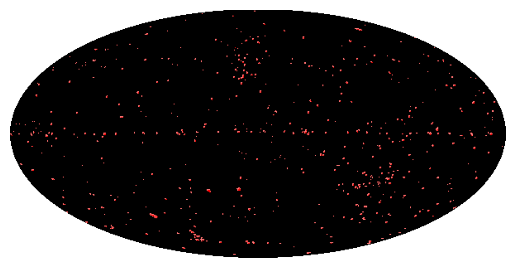

Number of DP2 tracts containing UBVRI standards: 191


In [12]:
# --- Imports ---------------------------------------------------------------
from pyvo import registry
from mocpy import MOC
import numpy as np
import astropy.units as u
import lsst.geom as geom
from lsst.daf.butler import Butler

# --- User options ----------------------------------------------------------
plot_ubvri_moc = True   # Set to False to skip the preview plot

# --- Step 1: Load Pancino+2022 UBVRI MOC -----------------------------------
CATALOGUE = "J/A+A/664/A109"
catalogue_coverage = MOC.from_vizier_table(CATALOGUE)

if plot_ubvri_moc:
    catalogue_coverage.display_preview()

# --- Step 2: Load Rubin DP2 skymap -----------------------------------------
repo = "dp2_prep"
collection = "LSSTCam/runs/DRP/DP2"

butler = Butler(repo, collections=collection)
skymap = butler.get("skyMap", skymap="lsst_cells_v2")

# --- Step 3: Helper functions ----------------------------------------------
def tract_polygon(tract):
    """Return list of (RA, Dec) vertices for a DP2 tract polygon."""
    poly = tract.getOuterSkyPolygon()
    verts = poly.getVertices()
    return [(geom.SpherePoint(v).getRa().asDegrees(),
             geom.SpherePoint(v).getDec().asDegrees())
            for v in verts]

def tract_moc(tract):
    """Convert a DP2 tract polygon into a mocpy MOC."""
    ra_list, dec_list = zip(*tract_polygon(tract))
    ra = np.array(ra_list) * u.deg
    dec = np.array(dec_list) * u.deg
    return MOC.from_polygon(ra, dec)

# --- Step 4: Identify DP2 tracts containing UBVRI standards ----------------
# Query all DP2 object-table dataset references
refs = list(
    butler.registry.queryDatasets(
        "object",
        collections=[collection],
        findFirst=True
    )
)

# Extract unique tract IDs
dp2_tracts = sorted({ref.dataId["tract"] for ref in refs})

# Intersect each tract with the UBVRI MOC
tracts_to_query = []

for tid in dp2_tracts:
    tmoc = tract_moc(skymap[tid])
    intersection = tmoc.intersection(catalogue_coverage)
    if not intersection.empty():
        tracts_to_query.append(tid)

# --- Final result ----------------------------------------------------------
print(f"Number of DP2 tracts containing UBVRI standards: {len(tracts_to_query)}")
tracts_to_query

tract_list = tracts_to_query


In [13]:
print(tract_list)

[2209, 2234, 2534, 2535, 2701, 2702, 2703, 2728, 3176, 3177, 3360, 3361, 3539, 3730, 3731, 3741, 3943, 3944, 4155, 4156, 4159, 4353, 4354, 4362, 4363, 4550, 4553, 4555, 4556, 4558, 4559, 4560, 4561, 4562, 4568, 4569, 4755, 4756, 4760, 4761, 4763, 4765, 4767, 4768, 4769, 4770, 4772, 4773, 4777, 4779, 4955, 4968, 4969, 4971, 4973, 4974, 4975, 4978, 5063, 5179, 5186, 5187, 5188, 5194, 5195, 5397, 5398, 5403, 5404, 5405, 5406, 5410, 5412, 5413, 5414, 5625, 5627, 5630, 5635, 5637, 5638, 5639, 5841, 5847, 5848, 5849, 5850, 5851, 5854, 5862, 5863, 5865, 5866, 5891, 5892, 6073, 6103, 6119, 6126, 6305, 6306, 6310, 6330, 6354, 6355, 6535, 6536, 6537, 6556, 6557, 6561, 6562, 6769, 6789, 6790, 6826, 6827, 6992, 7025, 7026, 7054, 7058, 7059, 7247, 7261, 7262, 7275, 7292, 7466, 7467, 7484, 7508, 7509, 7510, 7512, 7528, 7529, 7746, 7747, 7968, 7986, 7987, 7994, 8216, 8217, 8237, 8735, 8883, 9125, 9126, 9219, 9327, 9328, 9445, 9446, 9451, 9452, 9472, 9474, 9475, 9478, 9479, 9488, 9489, 9569, 9570, 957

In [14]:
# Define which of the nearly 1000 columns to download from the LSST ObjectTable...
if not useMatchFile:
    INCOLS = [
        'coord_ra',
        'coord_dec',
    ]
    bands="ugrizy"
    for band in bands:
        INCOLS += [
            f'{band}_psfFlux',
            f'{band}_psfFluxErr',
            f'{band}_ap12Flux',
            f'{band}_ap12FluxErr',
            f'{band}_extendedness',
            f'{band}_psfFlux_flag'
        ]


In [15]:
# Download stars from DP1 (excluding those from the Seagull Nebula)...
if not useMatchFile:
    LSST_stars_list = []

    for tractId in tract_list:

 #       if tract_dict[tractId] == 'Seagull':
 #           continue

 #       print(tractId, tract_dict[tractId])
        print(tractId)

        try:
    
            raw_LSST = butler.get('object', dataId={'skymap': 'lsst_cells_v2', 'tract': tractId}, 
                                    collections=[collection],
                                    parameters={"columns":INCOLS}).to_pandas()

            # Insert tractId as the first column
            raw_LSST.insert(0, 'tractId', tractId)  
    
            # Insert field name -- if known -- as the second column
   #         if tractId in tract_dict:
   #             field = tract_dict[tractId]
   #         else:
            field = 'unknown'
            raw_LSST.insert(1, 'field', field)  

            # Clean the catalog
            #sel  = (raw_LSST['detect_isPrimary'] == True)
            sel = (raw_LSST['r_psfFlux']/raw_LSST['r_psfFluxErr'] > 5)
            for band in ['g','r','i']:
                sel &= (raw_LSST[f'{band}_psfFlux_flag'] == 0)

            LSST = raw_LSST[sel]

            # Find just the (most likely) stars...
            sel_LSST_stars = (LSST['g_extendedness'] < 0.5) & (LSST['r_extendedness'] < 0.5)
            LSST_stars = LSST[sel_LSST_stars] 
            print(f"Number of objects: {len(LSST)}")
            print(f"Number of stars: {len(LSST_stars)}")

            # Append the dataframe to the list
            LSST_stars_list.append(LSST_stars) 

        # Catch any exception
        except Exception as e:

            print(f"An error occurred for tractId {tractId}: {e}")


    # Concatenate all dataframes in the list
    LSST_stars_all = pd.concat(LSST_stars_list, ignore_index=True)  
    print(f"Total number of stars: {len(LSST_stars_all)}")


In [16]:
if not useMatchFile:
    display(LSST_stars_all)


In [17]:
# Find the bounding (ra,dec)'s for the LSST EDFS field: 
#if not useMatchFile:
#    ra_min = LSST_stars_all.coord_ra.min()
#    ra_max = LSST_stars_all.coord_ra.max()
#    dec_min = LSST_stars_all.coord_dec.min()
#    dec_max = LSST_stars_all.coord_dec.max()

#    print(ra_min, ra_max, dec_min, dec_max)

## 5. Query UBVRcIc Catalog


In [18]:
# Invoke TAP service to UBVRcIc data....
if not useMatchFile:
    
    from pyvo import registry

    # Identify the catalogue
    CATALOGUE = "J/A+A/664/A109"
    catalogue_ivoid = f"ivo://CDS.VizieR/{CATALOGUE}"

    # Look up the VO resource
    voresource = registry.search(ivoid=catalogue_ivoid)[0]

    # Get the TAP service
    tap_service = voresource.get_service("tap")

    # Table name
    table_name = "J/A+A/664/A109/table5"

    # Query ALL rows and ALL columns
    query = f'SELECT * FROM "{table_name}"'

    # Execute synchronously
    results = tap_service.search(query)
    
    # Convert to an Astropy Table or Pandas DataFrame
    std_table = results.to_table()
    std_df = std_table.to_pandas()
    
    std_df





    

In [19]:
if not useMatchFile:
    display(std_df)

In [20]:
#combined_df.to_csv("ECFDS_PS1DR2_20250627.csv",index=False)

## 6. Match LSST and UBVRcIc stars

In [21]:
if not useMatchFile:
    matches, unmatched = cross_match_catalogs(LSST_stars_all, std_df, 
                                              'coord_ra', 'coord_dec', 
                                              'RAJ2000', 'DEJ2000')

In [22]:
if not useMatchFile:
    display(matches)

In [23]:
if not useMatchFile:
    matches.to_csv(matchFile,index=False)

In [24]:
if not useMatchFile:
    display(unmatched)

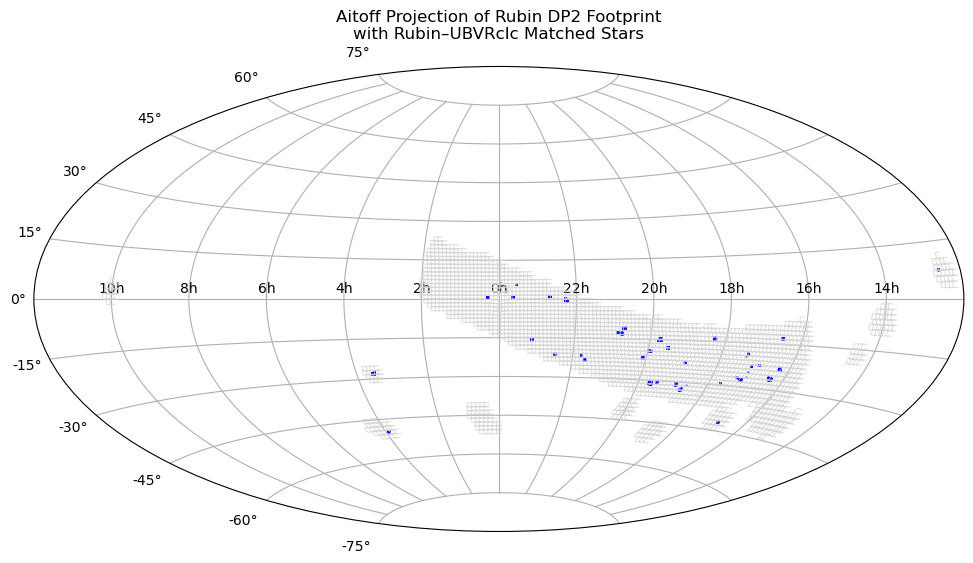

In [25]:
# Plot Aitoff sky plot of new match file...

#if not useMatchFile:
if True:
    
    # ------------------------------------------------------------
    # Extract RA/Dec from your final matches table
    # ------------------------------------------------------------
    ra = matches["coord_ra"].values
    dec = matches["coord_dec"].values

    # Convert RA to [-180, +180] degrees
    ra_wrapped = np.remainder(ra + 180.0, 360.0) - 180.0

    # Convert to radians
    ra_rad = np.deg2rad(-ra_wrapped)
    dec_rad = np.deg2rad(dec)

    # ------------------------------------------------------------
    # Self-contained: find ONLY the tracts that contain DP2 data
    # ------------------------------------------------------------
    _but = Butler(repo, collections=collection)

    # Query all object-table datasets in the DP2 collection
    refs = list(_but.registry.queryDatasets(
        "object",
        collections=[collection],
        findFirst=True
    ))

    # Extract unique tract IDs
    dp2_tracts = sorted({ref.dataId["tract"] for ref in refs})

    # Load skymap
    _skymap = _but.get("skyMap", skymap="lsst_cells_v2")

    # Convert tract polygons to RA/Dec
    def _tract_vertices_deg(tract):
        poly = tract.getOuterSkyPolygon()
        verts = poly.getVertices()
        ra_list, dec_list = [], []
        for v in verts:
            sp = geom.SpherePoint(v)
            ra_list.append(sp.getRa().asDegrees())
            dec_list.append(sp.getDec().asDegrees())
        return list(zip(ra_list, dec_list))

    # Build list of polygons for DP2 tracts only
    _dp2_vertices = [_tract_vertices_deg(_skymap[tid]) for tid in dp2_tracts]

    # ------------------------------------------------------------
    # Create Aitoff projection
    # ------------------------------------------------------------
    plt.figure(figsize=(12, 7))
    ax = plt.subplot(111, projection="aitoff")

    # ------------------------------------------------------------
    # 1. Plot ONLY Rubin DP2 tracts (not full skymap)
    # ------------------------------------------------------------
    for vertices in _dp2_vertices:
        ra_poly = np.array([v[0] for v in vertices])
        dec_poly = np.array([v[1] for v in vertices])

        # Wrap RA to [-180, +180]
        ra_poly_wrapped = np.remainder(ra_poly + 180.0, 360.0) - 180.0

        # Convert to radians
        ra_poly_rad = np.deg2rad(-ra_poly_wrapped)
        dec_poly_rad = np.deg2rad(dec_poly)

        ax.plot(ra_poly_rad, dec_poly_rad,
                color="lightgray", linewidth=0.8, alpha=0.7)

    # ------------------------------------------------------------
    # 2. Plot matched stars on top
    # ------------------------------------------------------------
    ax.scatter(ra_rad, dec_rad, s=1, alpha=0.5, color="blue")
    #ax.set_xticklabels(['14h','16h','18h','20h','22h','0h','2h','4h','6h','8h','10h'])
    ax.set_xticklabels(['10h','8h','6h','4h','2h','0h','22h','20h','18h','16h','14h'])

    ax.grid(True)
    plt.title("Aitoff Projection of Rubin DP2 Footprint\nwith Rubin–UBVRcIc Matched Stars", pad=20)

    # Save to PNG file
    plt.savefig(aitoffPlotFileName, dpi=200, bbox_inches="tight")

    # Plot to screen
    plt.show()


##  7. Add ABmag Columns to Matched Catalog Data Frame

In [26]:
# Copy matches to df...
df = matches.copy()

In [27]:
# Define common parameters
flux_bands = ['u', 'g', 'r', 'i', 'z', 'y']
offset = 31.4 # For magnitude calculation
sentinel_value = -9999.0

# Loop through each band to calculate both magnitude and magnitude error
for band in flux_bands:
    
    flux_col = f'{band}_psfFlux'
    flux_err_col = f'{band}_psfFluxErr'
    mag_col = f'{band}_psfMag'
    mag_err_col = f'{band}_psfMagErr'

    # Condition for valid flux (must be positive for log10 and division)
    valid_flux_condition = df[flux_col] > 0

    # Calculate magnitude
    df[mag_col] = np.where(valid_flux_condition,
                           -2.5 * np.log10(df[flux_col]) + offset,
                           sentinel_value)

    # Calculate magnitude error
    df[mag_err_col] = np.where(valid_flux_condition,
                               1.086 * df[flux_err_col] / df[flux_col],
                               sentinel_value)



/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [28]:
df

,tractId,field,coord_ra,coord_dec,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_extendedness,u_psfFlux_flag,...,g_psfMag,g_psfMagErr,r_psfMag,r_psfMagErr,i_psfMag,i_psfMagErr,z_psfMag,z_psfMagErr,y_psfMag,y_psfMagErr
0,2234,unknown,58.888459,-49.851082,NaN,NaN,NaN,NaN,NaN,True,...,16.559313,0.000316,16.131476,0.000290,16.049663,0.000171,15.961994,0.000232,15.946330,0.000775
1,2234,unknown,58.810008,-49.848706,NaN,NaN,NaN,NaN,NaN,True,...,18.054055,0.000642,16.769579,0.000313,15.995787,0.000183,15.561569,0.000185,15.237484,0.000700
2,2234,unknown,58.697833,-49.847908,NaN,NaN,NaN,NaN,NaN,True,...,20.154100,0.002122,18.934152,0.001068,17.967946,0.000455,17.548793,0.000538,17.340985,0.001673
3,2234,unknown,58.485919,-49.840704,NaN,NaN,NaN,NaN,NaN,True,...,20.833666,0.003224,20.484379,0.002561,20.360847,0.001819,20.347427,0.004401,20.361744,0.016992
4,2234,unknown,58.446841,-49.834766,NaN,NaN,NaN,NaN,NaN,True,...,19.972417,0.001767,18.763842,0.000892,18.047846,0.000392,17.735667,0.000640,17.583071,0.001839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8678,10805,unknown,188.484657,7.644225,235074.3900,168.371150,234175.0300,164.96594,0.0,False,...,16.725270,0.000117,16.258687,0.000090,16.079116,0.000143,-9999.000000,-9999.000000,-9999.000000,-9999.000000
8679,10805,unknown,188.462212,7.673424,34624.1200,76.293724,33823.3750,106.34611,0.0,False,...,19.213782,0.000420,18.848505,0.000334,18.705245,0.000557,-9999.000000,-9999.000000,-9999.000000,-9999.000000
8680,10805,unknown,188.532724,7.736702,57041.1500,97.194850,56835.9340,121.44758,0.0,False,...,18.366576,0.000275,17.911487,0.000217,17.781804,0.000361,-9999.000000,-9999.000000,-9999.000000,-9999.000000
8681,10805,unknown,188.442891,7.702207,2888.0442,52.657986,3097.6838,96.13993,1.0,False,...,20.224345,0.000809,18.939547,0.000352,17.700262,0.000265,-9999.000000,-9999.000000,-9999.000000,-9999.000000


In [29]:
for c in df.columns:
    print(c)

tractId
field
coord_ra
coord_dec
u_psfFlux
u_psfFluxErr
u_ap12Flux
u_ap12FluxErr
u_extendedness
u_psfFlux_flag
g_psfFlux
g_psfFluxErr
g_ap12Flux
g_ap12FluxErr
g_extendedness
g_psfFlux_flag
r_psfFlux
r_psfFluxErr
r_ap12Flux
r_ap12FluxErr
r_extendedness
r_psfFlux_flag
i_psfFlux
i_psfFluxErr
i_ap12Flux
i_ap12FluxErr
i_extendedness
i_psfFlux_flag
z_psfFlux
z_psfFluxErr
z_ap12Flux
z_ap12FluxErr
z_extendedness
z_psfFlux_flag
y_psfFlux
y_psfFluxErr
y_ap12Flux
y_ap12FluxErr
y_extendedness
y_psfFlux_flag
match_idx
separation_arcsec
match_recno
match_Id
match_GaiaEDR3
match_GaiaDR2
match_Name
match_Collect
match_RAJ2000
match_DEJ2000
match_RAGdeg
match_DEGdeg
match_Umag
match_e_Umag
match_nU
match_Bmag
match_e_Bmag
match_nB
match_Vmag
match_e_Vmag
match_nV
match_Rmag
match_e_Rmag
match_nR
match_Imag
match_e_Imag
match_nI
match_BinFlag
match_VarFlag
match_HighQual
match_Dist
match_b_Dist
match_B_Dist
match_E(B-V)
match_e_E(B-V)
match_RV
match_e_RV
match_MethRV
match_StarType
match_Methstar
match_

In [30]:
# Rename columns...
df.rename(columns={'coord_ra':'RA_LSST',
                   'coord_dec':'DEC_LSST',
                   'u_psfMag':'u_LSST',
                   'g_psfMag':'g_LSST',
                   'r_psfMag':'r_LSST',
                   'i_psfMag':'i_LSST',
                   'z_psfMag':'z_LSST',
                   'y_psfMag':'y_LSST',
                   'u_psfMagErr':'u_err_LSST',
                   'g_psfMagErr':'g_err_LSST',
                   'r_psfMagErr':'r_err_LSST',
                   'i_psfMagErr':'i_err_LSST',
                   'z_psfMagErr':'z_err_LSST',
                   'y_psfMagErr':'y_err_LSST',
                   'match_Umag':'U',
                   'match_Bmag':'B',
                   'match_Vmag':'V',
                   'match_Rmag':'R',
                   'match_Imag':'I',
                   'match_e_Umag':'U_err',
                   'match_e_Bmag':'B_err',
                   'match_e_Vmag':'V_err',
                   'match_e_Rmag':'R_err',
                   'match_e_Imag':'I_err',
                   'match_nU' : 'N_U',
                   'match_nB' : 'N_B',
                   'match_nV' : 'N_V',
                   'match_nR' : 'N_R',
                   'match_nI' : 'N_I'
                  },inplace=True)

df.head(5)

,tractId,field,RA_LSST,DEC_LSST,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_extendedness,u_psfFlux_flag,...,g_LSST,g_err_LSST,r_LSST,r_err_LSST,i_LSST,i_err_LSST,z_LSST,z_err_LSST,y_LSST,y_err_LSST
0,2234,unknown,58.888459,-49.851082,NaN,NaN,NaN,NaN,NaN,True,...,16.559313,0.000316,16.131476,0.000290,16.049663,0.000171,15.961994,0.000232,15.946330,0.000775
1,2234,unknown,58.810008,-49.848706,NaN,NaN,NaN,NaN,NaN,True,...,18.054055,0.000642,16.769579,0.000313,15.995787,0.000183,15.561569,0.000185,15.237484,0.000700
2,2234,unknown,58.697833,-49.847908,NaN,NaN,NaN,NaN,NaN,True,...,20.154100,0.002122,18.934152,0.001068,17.967946,0.000455,17.548793,0.000538,17.340985,0.001673
3,2234,unknown,58.485919,-49.840704,NaN,NaN,NaN,NaN,NaN,True,...,20.833666,0.003224,20.484379,0.002561,20.360847,0.001819,20.347427,0.004401,20.361744,0.016992
4,2234,unknown,58.446841,-49.834766,NaN,NaN,NaN,NaN,NaN,True,...,19.972417,0.001767,18.763842,0.000892,18.047846,0.000392,17.735667,0.000640,17.583071,0.001839


In [31]:
for c in df.columns:
    print(c)

tractId
field
RA_LSST
DEC_LSST
u_psfFlux
u_psfFluxErr
u_ap12Flux
u_ap12FluxErr
u_extendedness
u_psfFlux_flag
g_psfFlux
g_psfFluxErr
g_ap12Flux
g_ap12FluxErr
g_extendedness
g_psfFlux_flag
r_psfFlux
r_psfFluxErr
r_ap12Flux
r_ap12FluxErr
r_extendedness
r_psfFlux_flag
i_psfFlux
i_psfFluxErr
i_ap12Flux
i_ap12FluxErr
i_extendedness
i_psfFlux_flag
z_psfFlux
z_psfFluxErr
z_ap12Flux
z_ap12FluxErr
z_extendedness
z_psfFlux_flag
y_psfFlux
y_psfFluxErr
y_ap12Flux
y_ap12FluxErr
y_extendedness
y_psfFlux_flag
match_idx
separation_arcsec
match_recno
match_Id
match_GaiaEDR3
match_GaiaDR2
match_Name
match_Collect
match_RAJ2000
match_DEJ2000
match_RAGdeg
match_DEGdeg
U
U_err
N_U
B
B_err
N_B
V
V_err
N_V
R
R_err
N_R
I
I_err
N_I
match_BinFlag
match_VarFlag
match_HighQual
match_Dist
match_b_Dist
match_B_Dist
match_E(B-V)
match_e_E(B-V)
match_RV
match_e_RV
match_MethRV
match_StarType
match_Methstar
match_Teff
match_e_Teff
match_logg
match_e_logg
match_[Fe/H]
match_e_[Fe/H]
match_Methp
u_LSST
u_err_LSST
g_LSST


## 8. Add Color Columns to Matched Catalog Data Frame

In [32]:
# Add color columns...
df.loc[:,'ug_LSST'] = df.loc[:,'u_LSST'] - df.loc[:,'g_LSST']
df.loc[:,'gr_LSST'] = df.loc[:,'g_LSST'] - df.loc[:,'r_LSST']
df.loc[:,'ri_LSST'] = df.loc[:,'r_LSST'] - df.loc[:,'i_LSST']
df.loc[:,'iz_LSST'] = df.loc[:,'i_LSST'] - df.loc[:,'z_LSST']
df.loc[:,'zy_LSST'] = df.loc[:,'z_LSST'] - df.loc[:,'y_LSST']
df.loc[:,'gi_LSST'] = df.loc[:,'g_LSST'] - df.loc[:,'i_LSST']

df.loc[:,'UB'] = df.loc[:,'U'] - df.loc[:,'V']
df.loc[:,'BV'] = df.loc[:,'B'] - df.loc[:,'V']
df.loc[:,'VR'] = df.loc[:,'V'] - df.loc[:,'R']
df.loc[:,'RI'] = df.loc[:,'R'] - df.loc[:,'I']


In [33]:
# Insert dmag column...
df.loc[:,'dmag'] = -9999.

In [34]:
df

,tractId,field,RA_LSST,DEC_LSST,u_psfFlux,u_psfFluxErr,u_ap12Flux,u_ap12FluxErr,u_extendedness,u_psfFlux_flag,...,gr_LSST,ri_LSST,iz_LSST,zy_LSST,gi_LSST,UB,BV,VR,RI,dmag
0,2234,unknown,58.888459,-49.851082,NaN,NaN,NaN,NaN,NaN,True,...,0.427836,0.081813,0.087669,0.015664,0.509650,NaN,0.621,0.385,NaN,-9999.0
1,2234,unknown,58.810008,-49.848706,NaN,NaN,NaN,NaN,NaN,True,...,1.284476,0.773792,0.434218,0.324086,2.058268,NaN,1.476,0.979,NaN,-9999.0
2,2234,unknown,58.697833,-49.847908,NaN,NaN,NaN,NaN,NaN,True,...,1.219948,0.966205,0.419153,0.207808,2.186154,NaN,1.432,0.987,NaN,-9999.0
3,2234,unknown,58.485919,-49.840704,NaN,NaN,NaN,NaN,NaN,True,...,0.349287,0.123532,0.013420,-0.014317,0.472819,NaN,NaN,NaN,NaN,-9999.0
4,2234,unknown,58.446841,-49.834766,NaN,NaN,NaN,NaN,NaN,True,...,1.208575,0.715996,0.312180,0.152596,1.924571,NaN,NaN,NaN,NaN,-9999.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8678,10805,unknown,188.484657,7.644225,235074.3900,168.371150,234175.0300,164.96594,0.0,False,...,0.466583,0.179571,10015.079116,0.000000,0.646154,NaN,0.697,0.408,0.382,-9999.0
8679,10805,unknown,188.462212,7.673424,34624.1200,76.293724,33823.3750,106.34611,0.0,False,...,0.365277,0.143260,10017.705245,0.000000,0.508538,NaN,0.539,0.361,0.359,-9999.0
8680,10805,unknown,188.532724,7.736702,57041.1500,97.194850,56835.9340,121.44758,0.0,False,...,0.455089,0.129683,10016.781804,0.000000,0.584772,NaN,0.656,0.403,NaN,-9999.0
8681,10805,unknown,188.442891,7.702207,2888.0442,52.657986,3097.6838,96.13993,1.0,False,...,1.284798,1.239285,10016.700262,0.000000,2.524084,NaN,NaN,1.143,1.402,-9999.0


## 9. Create Initial Mask

In [35]:
mask1 = df["N_B"] >= 1
mask2 = df["N_V"] >= 3
mask3 = df["N_R"] >= 3
mask4 = df["N_I"] >= 1
mask5 = df["B_err"] <= 0.03
mask6 = df["V_err"] <= 0.03
mask7 = df["R_err"] <= 0.03
mask8 = df["I_err"] <= 0.03
mask9 = (df["B"] > 0.0) & (df["B"] < 30.0)
mask10 = (df["V"] > 0.0) & (df["V"] < 30.0)
mask11 = (df["R"] > 0.0) & (df["R"] < 30.0)
mask12 = (df["I"] > 0.0) & (df["I"] < 30.0)
mask_UBVRcIc = mask1 & mask2 & mask3 & mask4 & mask5 & mask6 & mask7 & mask8 & mask9 & mask10 & mask11 & mask12

mask1 = (df["g_LSST"] > 0.) & (df["g_LSST"] < 30.)
mask2 = (df["r_LSST"] > 0.) & (df["r_LSST"] < 30.)
mask3 = (df["i_LSST"] > 0.) & (df["i_LSST"] < 30.)
mask4 = (df["z_LSST"] > 0.) & (df["z_LSST"] < 30.)
mask5 = (df["y_LSST"] > 0.) & (df["y_LSST"] < 30.)
mask6 = df["g_err_LSST"] <= 0.02
mask7 = df["r_err_LSST"] <= 0.02
mask8 = df["i_err_LSST"] <= 0.02
mask9 = df["z_err_LSST"] <= 0.02
mask10 = df["y_err_LSST"] <= 0.02

mask_LSST = mask1 & mask2 & mask3 & mask4 & mask5 & mask6 & mask7 & mask8 & mask9 & mask10

mask = mask_UBVRcIc & mask_LSST


## 10. Make Backup Copies of Initial Mask and Original Data Frame

In [36]:
# Make a backup copy of original df...
df_orig = df.copy()

# Make a backup copy of original mask...
mask_orig = mask.copy()

## 11. Run Fit in Each Filter Band




# # # # # # # # # # # # # # # # # # # # 
u_LSST
# # # # # # # # # # # # # # # # # # # # 

u_LSST [-10.0, 10.0] 1
u_LSST [-1.0, 3.0] 1
*********************************
0 -1.0 3.0
*********************************
mask_branch length (before): 1189
dmag_branch length: 1188
color1_branch length: 1188
1188 1188 1188
1154 1154 1188
1152 1152 1188
1153 1153 1188
1153 1153 1188
mask_branch length (after): 1189
p_1 = -0.029395 ± 0.001556
p_0 = 0.744482 ± 0.001960

u_LSST - U = 0.744 + -0.029*$(U-B)$ [-0.3 < $(U-B)$ <= 2.8] [rms: 0.035]
u_LSST - U = -0.029*$(U-B)$ +0.744  [-0.3 < $(U-B)$ <= 2.8]  [rms: 0.035]

u_LSST - U = -0.029*$(U-B)$ +0.744  [-0.3 < $(U-B)$ <= 2.8]  [rms: 0.035]

U --> u_LSST

u_LSST - U = -0.029*$(U-B)$ +0.744  [-0.3 < $(U-B)$ <= 2.8]  [rms: 0.035]




# # # # # # # # # # # # # # # # # # # # 
g_LSST
# # # # # # # # # # # # # # # # # # # # 

g_LSST [-10.0, 10.0] 1
g_LSST [-0.2, 3.0] 1
*********************************
0 -0.2 3.0
*********************************
mask_bra

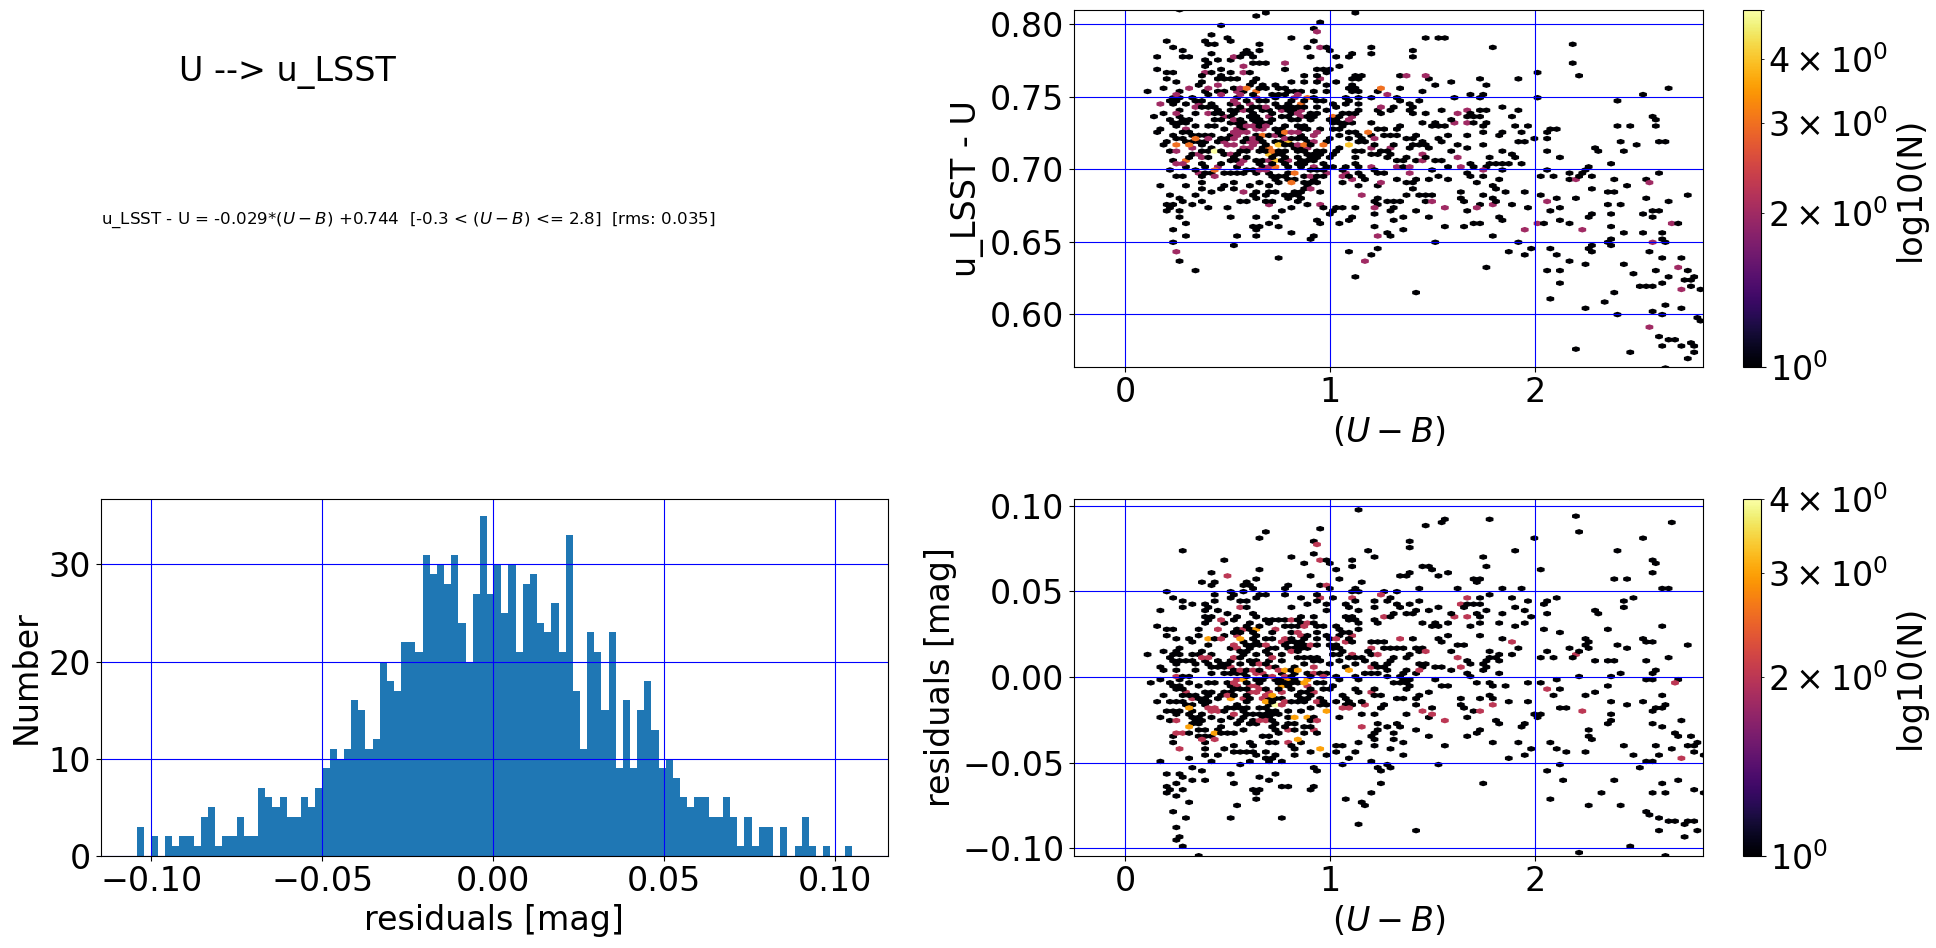

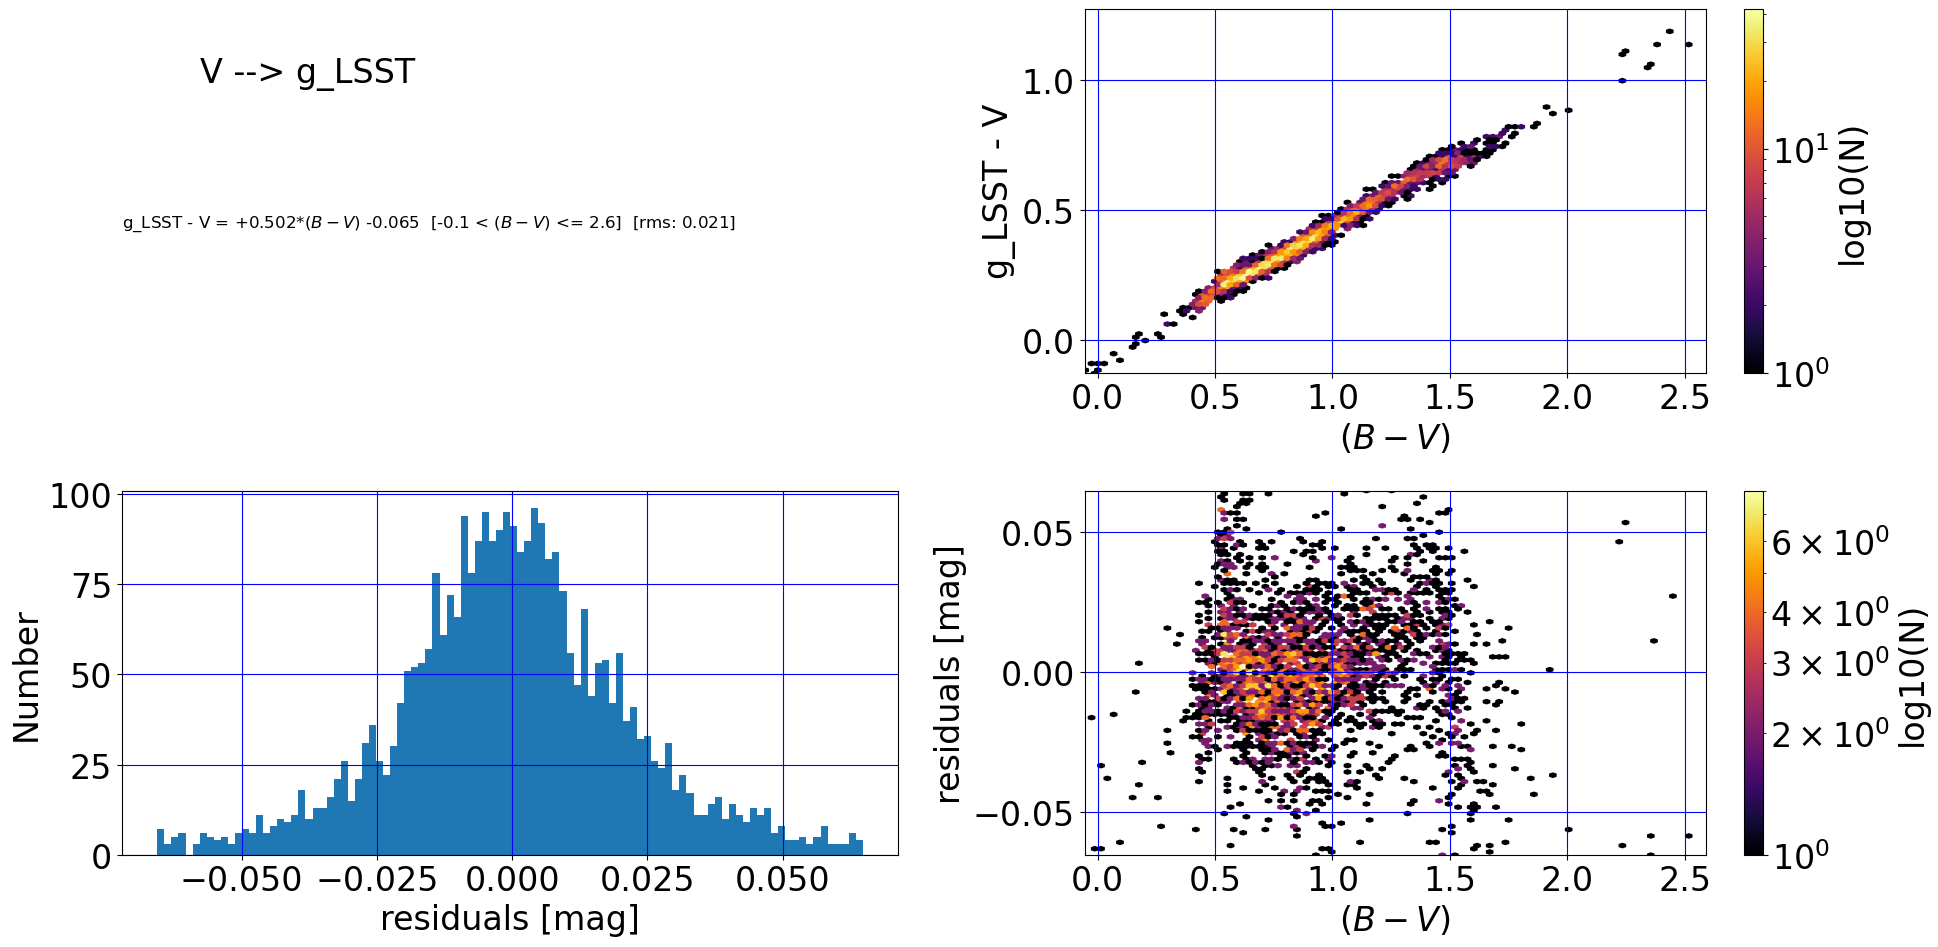

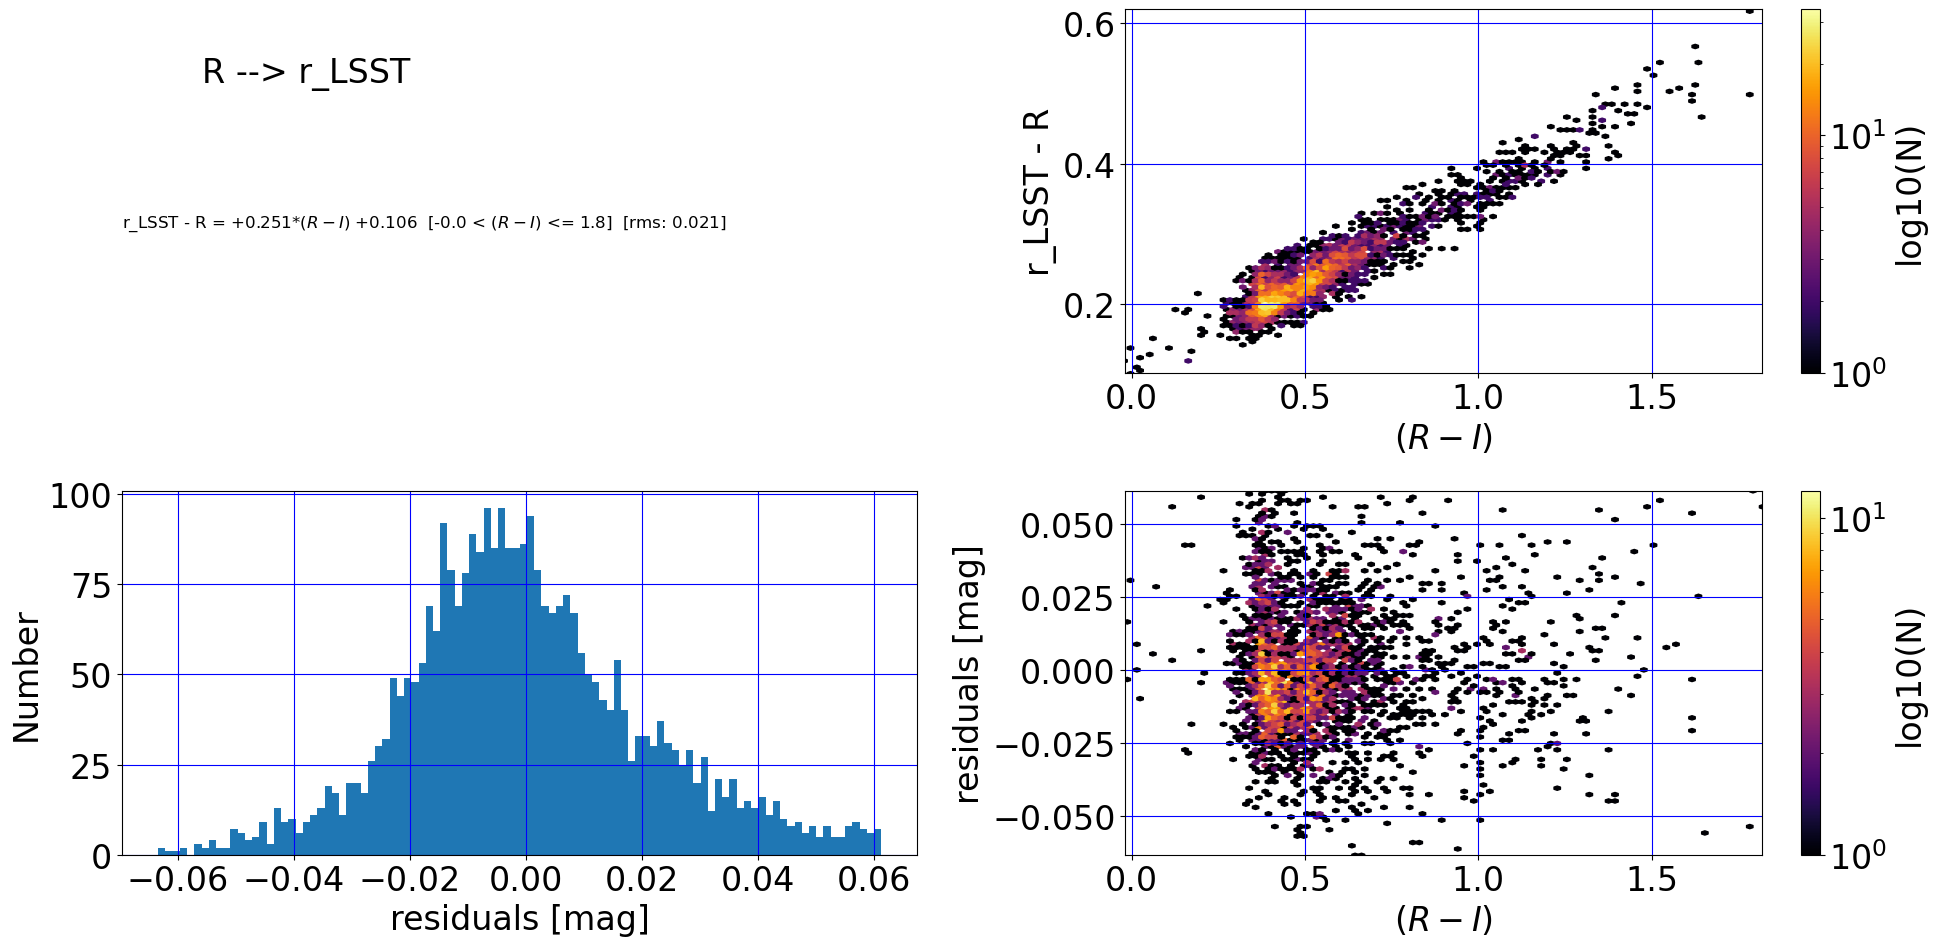

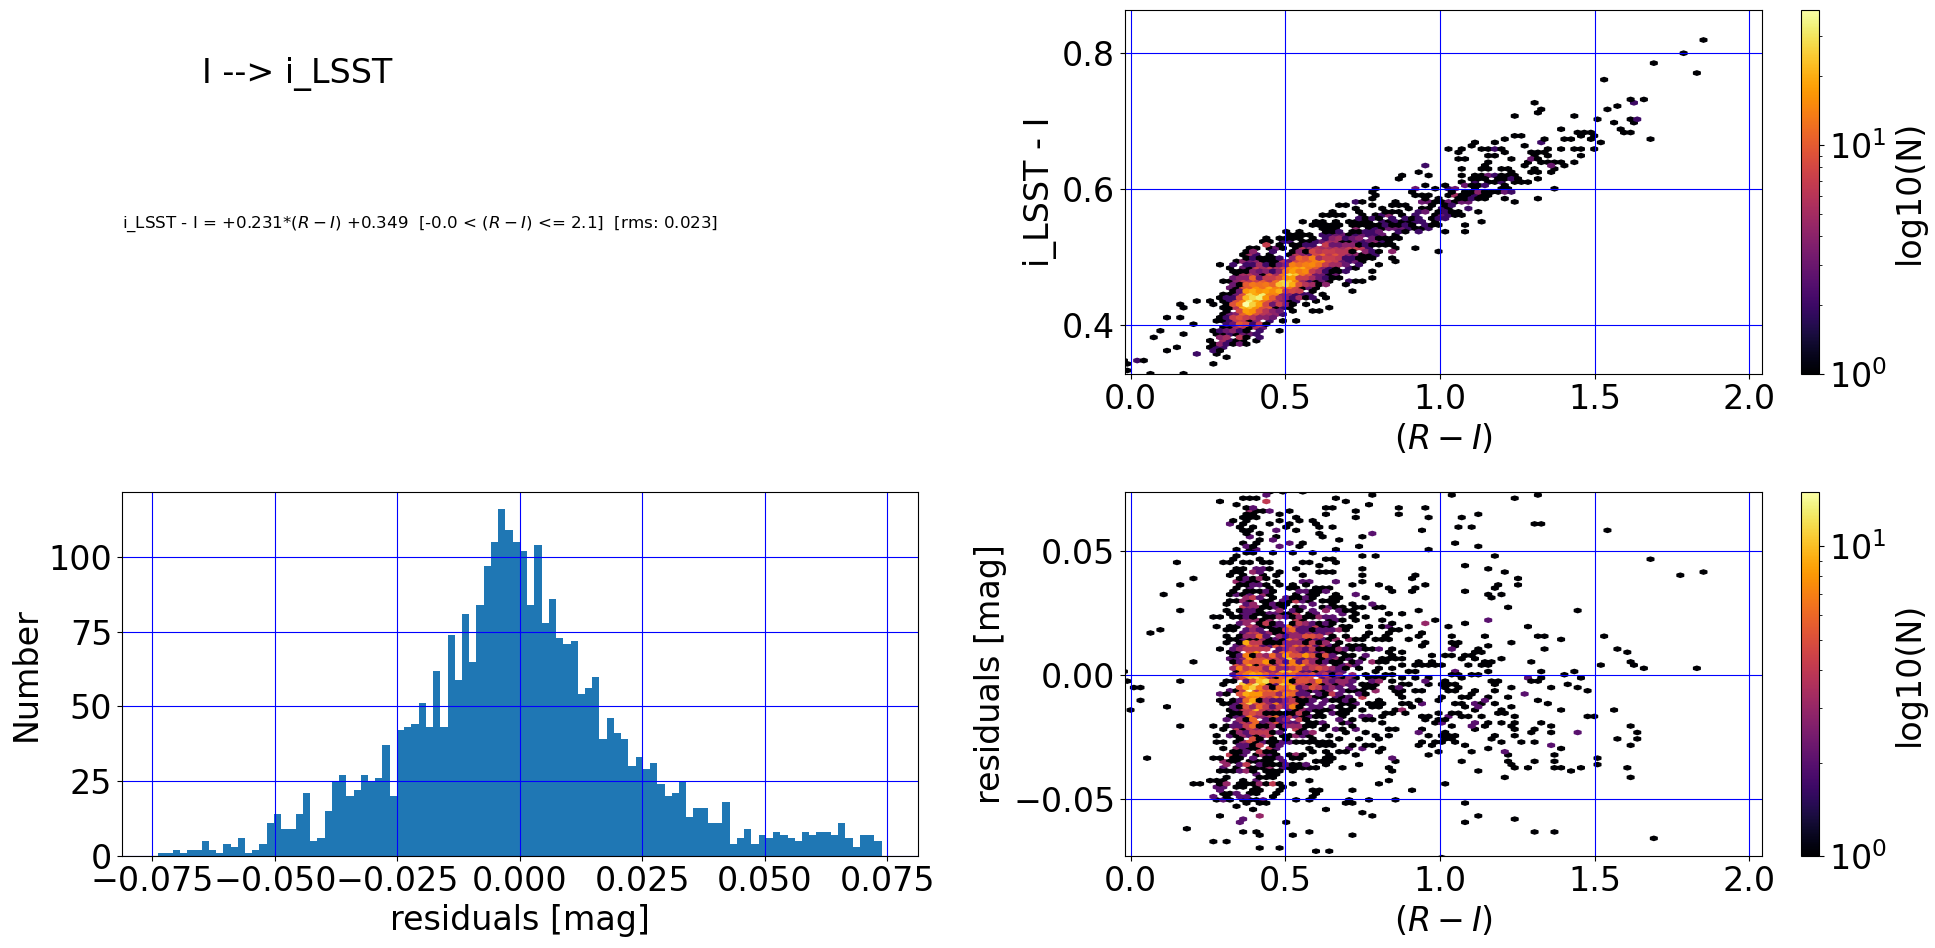

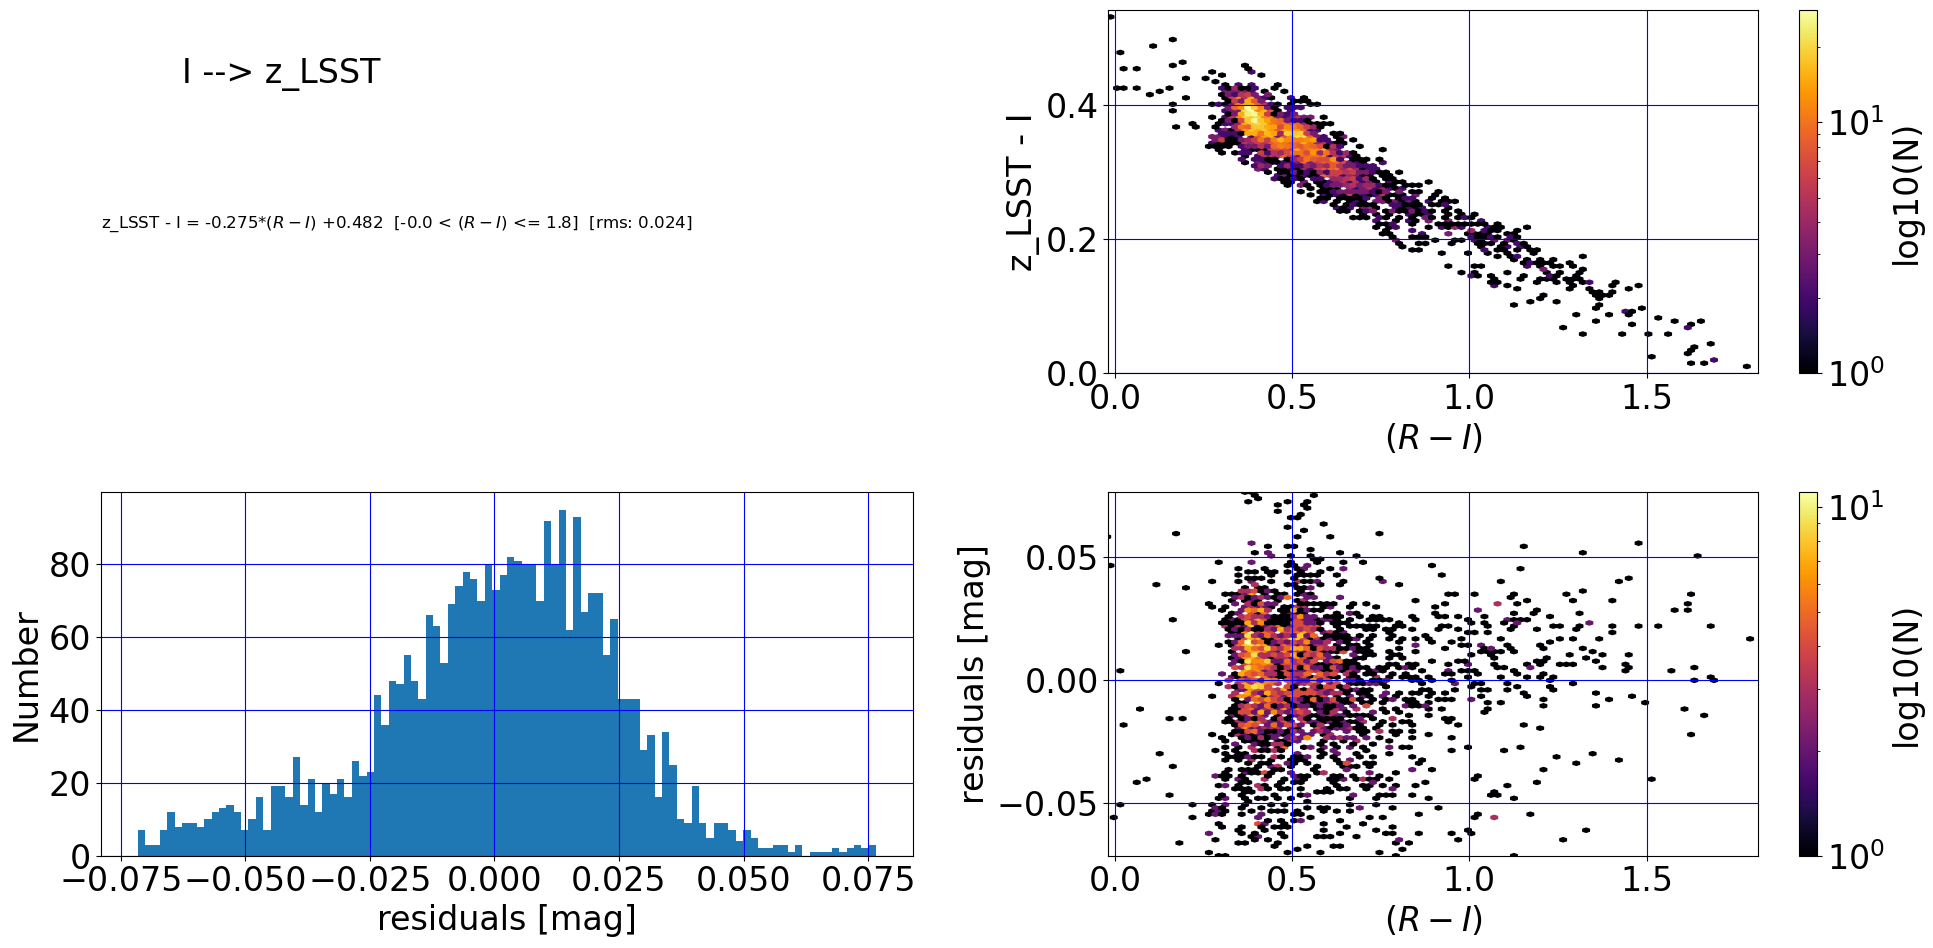

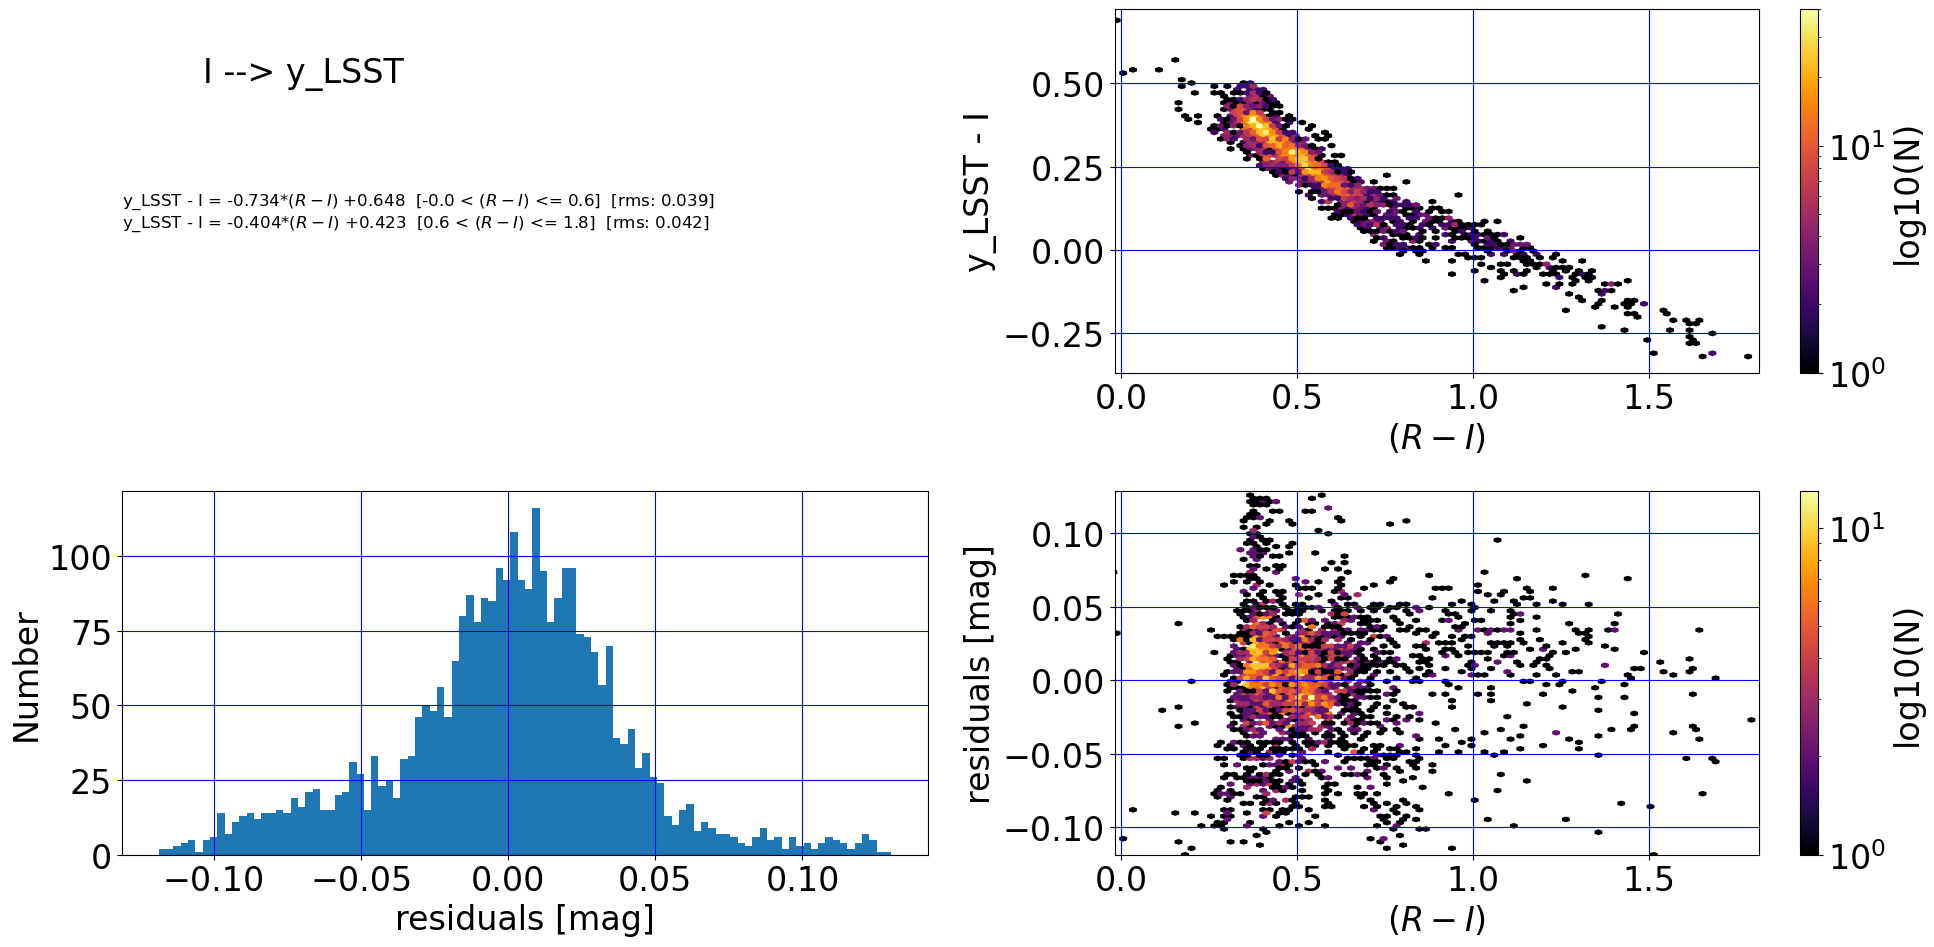

In [37]:
# --- Accumulator for ALL bands ---
qa_rows_all = []

# --- Main loop ---
for band in bandList:

    print("\n\n\n" + "# " * 20)
    print(band)
    print("# " * 20 + "\n")

    magName = band
    magName_match = matchBand_dict[band]
    color_name_1 = color_name_1_dict[band]
    colorLabel_1 = colorLabel_1_dict[band]

    # Create title/names for use in QA plots...
    title = f"{magName_match} --> {magName}"
    dmagName = f"{magName} - {magName_match}"

    # Grab the original version of df from the backup copy...
    df = df_orig.copy()

    # Grab the original version of mask from the backup copy...
    mask = mask_orig.copy()

    # Update dmag column for {$band} - {$band}_match...
    df.loc[:, 'dmag'] = df.loc[:, magName] - df.loc[:, magName_match]

    # Update mask...
    mask1 = (abs(df['dmag']) <= 10.)
    mask2 = ((df[color_name_1] > -3.) & (df[color_name_1] < 6.0))
    mask = mask & mask1 & mask2
    df = df[mask]

    # Calculate number of disjoint branches to fit...
    nbranches = len(color_limits_1_dict[band]) - 1
    if verbose > 0:
        print(band, color_limits_1_dict[band], nbranches)

    # Reset bluest color limit in bluest branch to color1_min
    #  and reddest color limit in reddest branch to color1_max, 
    #  after excluding above mask...
    dftmp = df
    color1_desc = dftmp[color_name_1].describe(percentiles=[0.0001, 0.9999])
    color1_min = math.floor(10*(color1_desc['0.01%']-0.05))/10.
    color1_max = math.ceil(10*(color1_desc['99.99%']+0.05))/10.
    color_limits_1_dict[band][0] = color1_min
    color_limits_1_dict[band][nbranches] = color1_max
    if verbose > 0:
        print(band, color_limits_1_dict[band], nbranches)

    # Iterate, with sigma-clipping...
    color1_list = []
    dmag_list = []
    res_list = []
    mask_list = []
    plot1Text = ''

    for ibranch in range(nbranches):

        print('*********************************')
        print(ibranch, color_limits_1_dict[band][ibranch], color_limits_1_dict[band][ibranch+1])
        print('*********************************')

        mask_branch = ((df[color_name_1] > color_limits_1_dict[band][ibranch]) &
                       (df[color_name_1] <= color_limits_1_dict[band][ibranch+1]))
        df_branch = df[mask_branch].copy()

        # ... and extract dmag's and color1's for this branch...
        dmag_branch = df_branch.loc[:, 'dmag']
        color1_branch = df_branch.loc[:, color_name_1]

        # If there are no valid colors on this branch, continue to next branch...
        if len(color1_branch) < 1:
            continue

        # Perform fit for each disjoint branch...
        print("mask_branch length (before):", len(mask_branch))
        print("dmag_branch length:", len(dmag_branch))
        print("color1_branch length:", len(color1_branch))

        p_branch, perr_branch, color1_branch, dmag_branch, res_branch, stddev_branch = \
            poly_fit_with_sigma_clip(color1_branch, dmag_branch, degree=norder)

        print("mask_branch length (after):", len(mask_branch))

        # NEW:  13 June 2026:
        # Update branch color limits based on clipped data
        lo_new = np.min(color1_branch)
        hi_new = np.max(color1_branch)
        # Store updated limits
        color_limits_1_dict[band][ibranch] = lo_new
        color_limits_1_dict[band][ibranch+1] = hi_new

        
        # Print coefficients and estimated statistical errors in the coefficients
        for i, (p, perr) in enumerate(zip(p_branch, perr_branch)):
            print(f'p_{len(p_branch)-i-1} = {p:.6f} ± {perr:.6f}')

        # --- Build Markdown table row and add to global list ---
        eq_str = make_eq_str(dmagName, p_branch, colorLabel_1, norder)
        range_str = make_range_str(color_limits_1_dict[band], colorLabel_1, ibranch)
        outputFileName = make_output_filename(
            qaFileBaseName, magName, magName_match, color_name_1, norder
        )
        link_str = f"[link](_static/plots/{outputFileName})"
        title_math = latexify_name(title)
        title_math = title_math.replace("-->", "\\to")
        qa_rows_all.append({
            "Conversion": f"${title_math}$",
            "Transformation Equation": eq_str,
            "RMS": round(stddev_branch, 3),
            "Applicable Color Range": range_str,
            "QA Plot": link_str
        })

        # Keep original plot1Text for QA plots
        if norder == 1:
            plot1Text1 = f"{dmagName} = {p_branch[1]:.3f} + {p_branch[0]:.3f}*{colorLabel_1} " \
                         f"[{color_limits_1_dict[band][ibranch]:.1f} < {colorLabel_1} <= {color_limits_1_dict[band][ibranch+1]:.1f}] " \
                         f"[rms: {stddev_branch:.3f}]"
        elif norder == 2:
            plot1Text1 = f"{dmagName} = {p_branch[2]:.3f} + {p_branch[1]:.3f}*{colorLabel_1} " \
                         f"+ {p_branch[0]:.3f}*{colorLabel_1}^2  " \
                         f"[{color_limits_1_dict[band][ibranch]:.1f} < {colorLabel_1} <= {color_limits_1_dict[band][ibranch+1]:.1f}] " \
                         f"[rms: {stddev_branch:.3f}]"
        else:
            plot1Text1 = ''

        plot1Text1_old = f"{plot1Text}\n{plot1Text1}"
        print(plot1Text1_old)

        plot1Text1 = make_plot_text(
            dmagName, p_branch, colorLabel_1, norder,
            color_limits_1_dict[band], ibranch, stddev_branch
        )
        plot1Text = f"{plot1Text}\n{plot1Text1}"
        print(plot1Text1)
        print(plot1Text)


        # Append branch df and mask to the df_list and mask_list lists, respectively...
        #df_list.append(df_branch.copy())
        #mask_list.append(mask_branch.copy())
        color1_list.append(color1_branch.copy())
        dmag_list.append(dmag_branch.copy())
        res_list.append(res_branch.copy())
        mask_list.append(mask_branch.copy())

    # Concatenate the color1, dmag, res, and mask lists for all the branches...
    color1 = pd.Series(np.concatenate(color1_list))
    dmag = pd.Series(np.concatenate(dmag_list))
    res = pd.Series(np.concatenate(res_list))
    mask = pd.Series(np.concatenate(mask_list))

    # Calculate the standard deviation for the full piecewise fit...
    stddev = res.std()

    # Output best fits to screen...
    if verbose > 0:
        print("")
        print(title)
        print(plot1Text)
        print("")

    # Create QA plots...
    outputFileName = make_output_filename(
        qaFileBaseName, magName, magName_match, color_name_1, norder
    )
    status = transform1ColorQAPlots1a(
        dmag, color1, res, norder, title, plot1Text,
        dmagName, colorLabel_1, stddev, outputFileName
    )

# --- After ALL bands processed: display one big table ---
if qa_rows_all:
    qa_df_all = pd.DataFrame(qa_rows_all)
    # Generate Markdown string (older Pandas: escape removal trick)
    md_table_str = qa_df_all.to_markdown(index=False)
    md_table_str = md_table_str.replace(r'\_', '_')
    print(md_table_str)  # raw Markdown table source

    if write_md_file:
        with open(md_filename, "w") as f:
            f.write(md_table_str)
        print(f"\nMarkdown table written to: {md_filename}")


In [38]:
raise StopExecution

## 12.  Sandbox